# Keysight Oscilloscope Examples

In [64]:
import matplotlib.pyplot as plt
from IPython.display import Image

from inspy.instrument.oscilloscope import OscilloscopeKeysightDSOX1202G

ADDRESS = "USB0::10893::919::CN61444220::INSTR"

In [65]:
scope: OscilloscopeKeysightDSOX1202G = OscilloscopeKeysightDSOX1202G(ADDRESS)
scope.connect()

## Simple capture
Channel 1 is connected to an Arbitrary Waveform Generator outputting a 1 kHz sine wave
with 0.2 V (peak-to-peak) amplitude.

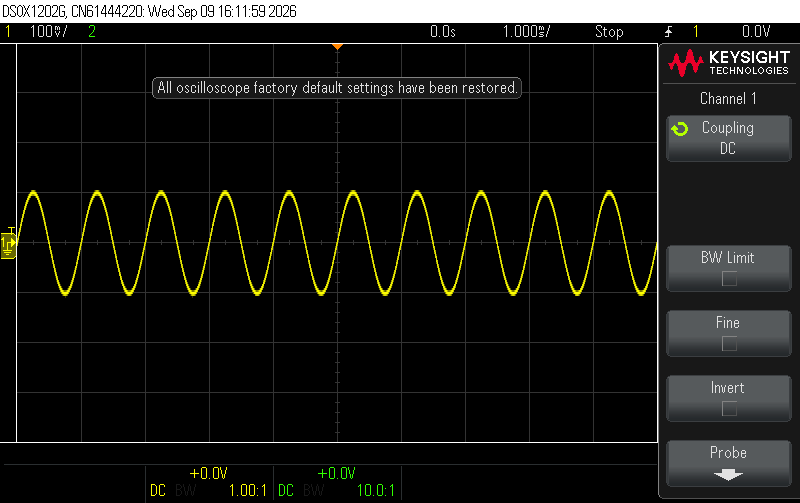

In [67]:
scope.reset()
scope.set_timebase(timebase_range=10e-3)
scope.set_channel(channel=1, voltage_range=0.8, attenuation=1.0)
scope.set_trigger(channel=1, level=0.0, slope="POS", sweep="NORM")
scope.digitize()
Image(scope.get_screenshot())

In [68]:
print(f"Amplitude: {scope.get_measurement_amplitude(channel=1):6.2f} V")
print(f"Frequency: {scope.get_measurement_frequency(channel=1):6.2f} Hz")

Amplitude:   0.21 V
Frequency: 999.80 Hz


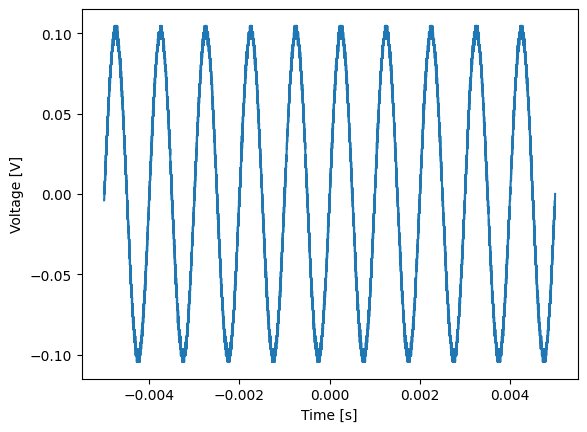

In [69]:
times, voltages = scope.get_waveform(channel=1)
plt.plot(times, voltages)
plt.xlabel("Time [s]")
plt.ylabel("Voltage [V]");

## Internal waveform generator capture
Channel 2 is connected to the output of the scope's built in waveform
generator.

Amplitude:   0.41 V
Frequency: 500.08 Hz


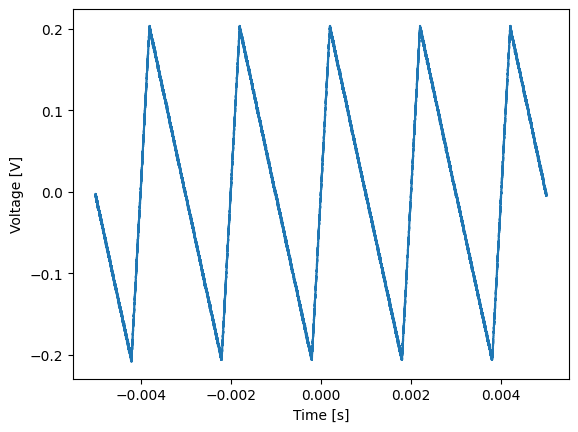

In [59]:
scope.reset()
scope.set_wavegen(
    function="RAMP",
    frequency=500,
    voltage_high=0.2,
    voltage_low=-0.2,
    output_impedance="ONEM",
    ramp_symmetry=0.2,
)
scope.set_wavegen_output_enable(True)

scope.set_timebase(timebase_range=10e-3)
scope.set_channel(channel=2, voltage_range=0.5, attenuation=1.0)
scope.set_trigger(
    channel=2,
    level=0.0,
    slope="POS",
    sweep="NORM",
)

scope.digitize()

print(f"Amplitude: {scope.get_measurement_amplitude(channel=2):6.2f} V")
print(f"Frequency: {scope.get_measurement_frequency(channel=2):6.2f} Hz")

times, voltages = scope.get_waveform(channel=2)
plt.plot(times, voltages)
plt.xlabel("Time [s]")
plt.ylabel("Voltage [V]");

In [60]:
scope.disconnect()